[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PCML_PEQ_2026/blob/main/JupyterNotebooks/PEQ_Colloquium_Tutorial_1.ipynb)

# Tutorial 1: Constrained Neural Networks for a Membrane Separator
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

This hands-on tutorial is given at the **end of the workshop** to reinforce the concepts of Modules 1-3 with a membrane
separator (the same type of system used in the Module 2 and Module 3 notebooks). In this tutorial, we will:

1. Generate noisy measurements for a membrane separation process.
2. Train an unconstrained neural network.
3. Train a physics-informed neural network (PINN) whose objective penalizes violations of the mass balances.
4. Train a physics-constrained neural network (PCNN) with hard equality constraints (Pyomo/Ipopt).
5. Compare predictive accuracy and conservation.
6. Quantify parameter uncertainty with a constrained parametric bootstrap and propagate it to predictions.

### Connection to the slides (Modules 1-3)

The equations below use the notation of the slides. Where the code uses a different name, it is given in parentheses.

| Concept | Notation (code name) | Slides |
|---|---|---|
| Unconstrained NN | $\widehat q=\mathrm{ML}_\theta(x)$ with $p=16$ params | Feedforward NN (Module 1) |
| Data loss | $L_d(\theta)$ | $L_d(\theta)=-\log f(\mathbf{y}\mid\theta)$ up to constants (Modules 1-3) |
| Regularization | $\kappa\,\rho(\theta)$ (`alpha`) | Regularization = Gaussian prior (Modules 1 and 3) |
| PINN | $L_d(\theta)+\kappa\,\rho(\theta)+\lambda_p L_p(\theta)$ (`lam`) | Physics-informed NN with weight $\lambda_p$ (Module 2) |
| PCNN | $\min_\theta L_d(\theta)+\kappa\,\rho(\theta)$ s.t. balances on the weights (Pyomo/Ipopt) | Physics-constrained NN, simultaneous approach (Module 2); constraints on parameters (Module 3) |
| Constrained parametric bootstrap | Samples $\theta_s$, predictions $\widehat q_s$, $s=1,\dots,N_s$ | Sampling-based UQ (Module 3) |

Here the PCNN enforces the balances through **linear constraints on the NN weights**, solved with Ipopt; in the Module 2
notebook the balances are built into the architecture instead. Both give exact conservation.

### Before the workshop

    conda create -n pcml -c conda-forge python=3.11 numpy matplotlib pyomo ipopt jupyterlab ipykernel
    conda activate pcml
    python -m pip install torch
    jupyter lab

Installing Pyomo alone does not install the Ipopt executable (the conda-forge `ipopt` package does). PyTorch is used for
the unconstrained NN and the penalty-based PINN; Pyomo/Ipopt is used only for the hard-constrained PCNN and its bootstrap
refits.

In [ ]:
# On Google Colab, install Pyomo and the Ipopt solver (takes about a minute).
# Locally, use the conda environment described above instead.
import os
import sys

if "google.colab" in sys.modules:
    !pip install -q pyomo idaes-pse
    !idaes get-extensions --to ./bin
    os.environ["PATH"] += os.pathsep + os.path.abspath("bin")


In [1]:
import time
import shutil
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import pyomo.environ as pyo
from pyomo.opt import check_optimal_termination

SEED = 26
rng = np.random.default_rng(SEED)

torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have an external LaTeX installation
    "font.family": "serif",
    "axes.labelsize": 16,
    "axes.titlesize": 17,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
})

### 1. Define the membrane experiment

A steady-state membrane separates a liquid feed into permeate and retentate.

Assume:
- No reaction, accumulation, leaks, or solute loss.
- Fixed temperature, membrane area, feed flow, and feed composition.
- Transmembrane pressure is the only varying input.

The feed conditions are

$$F=100\ \mathrm{kg\,h^{-1}}, \qquad c_f=0.02$$

Here, $c_f$ is the solute mass fraction: kg solute per kg solution.
Pressure varies over $P\in[5,15]$ bar.

The outputs are:
- $F_p,F_r$: permeate and retentate total mass flows
- $S_p,S_r$: permeate and retentate solute mass flows

All four flows have units of kg/h.

The conservation equations are

$$F_p+F_r=F$$

$$S_p+S_r=Fc_f$$

Concentrations are recovered from

$$c_p=\frac{S_p}{F_p},\qquad c_r=\frac{S_r}{F_r}$$

Thus, the solute balance is equivalently

$$F_pc_p+F_rc_r=Fc_f$$

The solvent balance follows by subtraction, so it is not an additional
independent constraint.

### Scale the outputs

Define

$$q=\left(\frac{F_p}{F},\frac{F_r}{F},
          \frac{S_p}{Fc_f},\frac{S_r}{Fc_f}\right)$$

Using Python's zero-based indexing, the balance residuals become

$$g_M(q)=q_0+q_1-1,\qquad g_S(q)=q_2+q_3-1$$

Scaling prevents the larger total flows from dominating the fitting objective.

### Generate synthetic measurements

We generate a pressure-dependent total recovery $r(P)$ and solute split $s(P)$:

$$q^*(P)=(r,1-r,s,1-s)$$

These are illustrative synthetic relationships, not a calibrated membrane
transport model. The neural networks do not receive these relationships.

Assume independent Gaussian measurement noise with standard deviations

$$\boldsymbol{\sigma}=(0.02,\ 0.02,\ 0.002,\ 0.002)$$

for the scaled outputs $(q_0,q_1,q_2,q_3)$, respectively.

These correspond to physical measurement standard deviations of
$(2,\ 2,\ 0.004,\ 0.004)$ kg/h.

This assumes independently measured mass flows. If solute flows are calculated
from measured flow rates and concentrations, their measurement errors will
generally be correlated.

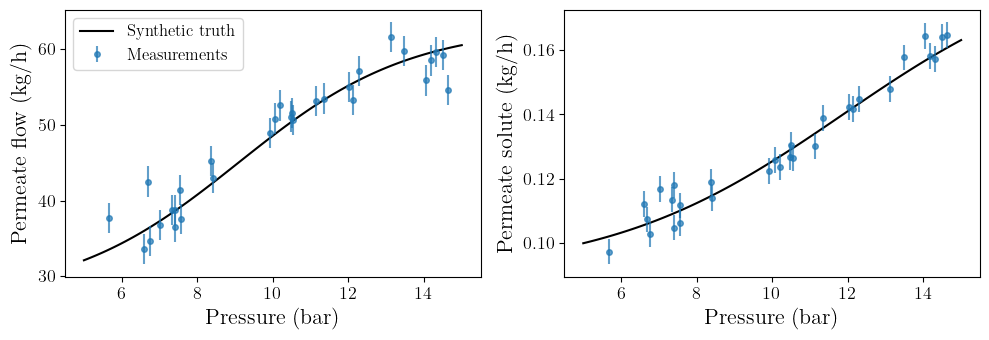

Observed maximum scaled balance errors: [0.06943635 0.00509434]


In [2]:
F, cf = 100.0, 0.02
scale = np.array([F, F, F*cf, F*cf])

# Noise SD for normalized [Fp, Fr, Sp, Sr]
sigma = np.array([0.02, 0.02, 0.002, 0.002])

labels = [
    "Permeate flow",
    "Retentate flow",
    "Permeate solute",
    "Retentate solute"
]

def scaled_pressure(P):
    return (np.asarray(P) - 10.0) / 5.0

def truth(P):
    x = scaled_pressure(P)
    r = 0.45 + 0.18*np.tanh(1.1*x + 0.2)
    s = 0.07 + 0.025*np.tanh(0.8*x - 0.3)
    return np.column_stack([r, 1-r, s, 1-s])

P_train = np.sort(rng.uniform(5.0, 15.0, 30))
P_test = np.linspace(5.05, 14.95, 61)
P_grid = np.linspace(5.0, 15.0, 101)

q_true = truth(P_train)
q_obs = q_true + rng.normal(size=q_true.shape)*sigma

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for ax, j in zip(axes, [0, 2]):
    ax.plot(
        P_grid, truth(P_grid)[:, j]*scale[j],
        "k-", label="Synthetic truth"
    )
    ax.errorbar(
        P_train,
        q_obs[:, j]*scale[j],
        yerr=sigma[j]*scale[j],
        fmt="o", ms=4, alpha=0.7,
        label="Measurements"
    )
    ax.set(
        xlabel="Pressure (bar)",
        ylabel=labels[j] + " (kg/h)"
    )

axes[0].legend()
plt.tight_layout()
plt.show()

print(
    "Observed maximum scaled balance errors:",
    np.max(
        np.abs(q_obs[:, [0, 2]] + q_obs[:, [1, 3]] - 1),
        axis=0
    )
)

### 2. Define and train an unconstrained neural network

Use one hidden layer with two 'tanh' neurons:

$$x=\frac{P-10}{5}$$

$$h_j=\tanh(a_jx+b_j), \qquad j=1,2$$

$$\widehat q_k=d_k+\sum_{j=1}^{2}V_{jk}h_j,
\qquad k=0,1,2,3$$

We write the network compactly as $\widehat q=\mathrm{ML}_\theta(x)$, where $\theta$ collects all weights and biases.

Therefore, the total number of model parameters is:

$$p=2+2+8+4=16$$

For a batch of $N=|\mathcal S|$ samples, the input matrix has shape $N\times1$,
the hidden-activation matrix has shape $N\times2$, and the output matrix
has shape $N\times4$.

All weights and biases are trainable.

### Training objective

The noise-weighted data-fitting loss is

$$L_d(\theta)=
\frac{1}{4N}\sum_{\omega\in\mathcal S}\sum_{k=0}^{3}
\left(
\frac{\widehat q_k(P_\omega;\theta)-q_{\omega k}}{\sigma_k}
\right)^2$$

where $q_{\omega k}$ are the scaled measurements of experiment $\omega\in\mathcal S$.

Add a regularization term

$$\rho(\theta)=\frac{1}{p}\|\theta\|^2$$

The unconstrained NN solves

$$\min_\theta L_d(\theta)+\kappa\,\rho(\theta),
\qquad \kappa=0.1\ (\texttt{alpha})$$

There are no physics constraints or parameter bounds in this fit.

### Implementation in PyTorch

We use `nn.Linear` layers and a tanh activation. PyTorch calculates
gradients using automatic differentiation.

Training uses:
1. Adam for the initial optimization.
2. L-BFGS for refinement of this small, full-batch problem.

The same training function will subsequently train the PINN by adding
a physics penalty. Setting its penalty weight to zero gives the
unconstrained NN.

PyTorch stores a linear layer's weight matrix as
(number of outputs, number of inputs). Therefore:
- The hidden-layer weight matrix has shape $(2,1)$.
- The output-layer weight matrix has shape $(4,2)$.
- The latter is transposed when exporting our mathematical matrix $V$.

All three models use the same architecture, data, initialization, and
regularization. However, NN/PINN use PyTorch optimizers while PCNN uses
IPOPT. Comparisons therefore reflect optimization effects as well as
the physics formulation.

These problems are nonconvex; global optimality is not guaranteed.

In [3]:
H, alpha = 2, 0.1

init = {
    "a": np.array([0.7, 1.3]),
    "b": np.array([-0.2, 0.2]),
    "V": np.array([
        [0.08, -0.08, 0.01, -0.01],
        [0.08, -0.08, 0.01, -0.01]
    ]),
    "d": np.array([0.45, 0.55, 0.07, 0.93])
}


def predict(theta, P):
    """NumPy prediction interface shared by all three models."""
    hidden = np.tanh(
        scaled_pressure(P)[:, None]*theta["a"] + theta["b"]
    )
    return hidden @ theta["V"] + theta["d"]


class MembraneNN(nn.Module):
    def __init__(self, start=None):
        super().__init__()

        start = init if start is None else start

        self.hidden = nn.Linear(1, H)
        self.output = nn.Linear(H, 4)

        # Match the initialization used later in Pyomo.
        with torch.no_grad():
            self.hidden.weight.copy_(
                torch.tensor(start["a"][:, None])
            )
            self.hidden.bias.copy_(
                torch.tensor(start["b"])
            )
            self.output.weight.copy_(
                torch.tensor(start["V"].T)
            )
            self.output.bias.copy_(
                torch.tensor(start["d"])
            )

    def forward(self, x):
        h = torch.tanh(self.hidden(x))
        return self.output(h)


def fit_torch(Y, lam=0.0, epochs=3000, lr=0.01):
    """
    lam = 0: unconstrained NN
    lam > 0: penalty-based PINN
    """
    net = MembraneNN()

    x = torch.tensor(scaled_pressure(P_train)[:, None])
    target = torch.tensor(Y)
    noise = torch.tensor(sigma)

    def losses():
        q = net(x)

        # Noise-weighted data-fitting loss.
        data = torch.mean(((q - target)/noise)**2)

        # Mean squared magnitude of all trainable parameters.
        parameter_vector = torch.cat([
            p.reshape(-1) for p in net.parameters()
        ])
        reg = parameter_vector.square().mean()

        # Scaled total-mass and solute-balance residuals.
        residuals = torch.stack(
            (
                q[:, 0] + q[:, 1] - 1,
                q[:, 2] + q[:, 3] - 1
            ),
            dim=1
        )

        balance_variance = torch.tensor([
            sigma[0]**2 + sigma[1]**2,
            sigma[2]**2 + sigma[3]**2
        ])
        
        physics = (residuals.square()/balance_variance).mean()

        total = data + alpha*reg + lam*physics
        return total, data, physics

    # Stage 1: Adam.
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    history = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        total, _, _ = losses()

        if not torch.isfinite(total):
            raise RuntimeError("Nonfinite training loss")

        total.backward()
        optimizer.step()

        if epoch % 100 == 0:
            history.append((epoch, total.item()))

    # Stage 2: full-batch L-BFGS refinement.
    optimizer = torch.optim.LBFGS(
        net.parameters(),
        max_iter=1000,
        tolerance_grad=1e-8,
        tolerance_change=1e-12,
        line_search_fn="strong_wolfe"
    )

    def closure():
        optimizer.zero_grad()
        total, _, _ = losses()
        total.backward()
        return total

    optimizer.step(closure)

    # Inspect the final objective and gradient.
    total, data, physics = losses()
    grads = torch.autograd.grad(
        total, tuple(net.parameters())
    )
    grad_max = max(g.abs().max().item() for g in grads)

    if not np.isfinite(total.item()):
        raise RuntimeError("Nonfinite final loss")

    if grad_max > 1e-3:
        print(
            "Convergence warning: inspect final gradient:",
            grad_max
        )

    # Export weights into the shared NumPy representation.
    theta = {
        "a": net.hidden.weight.detach().numpy()[:, 0].copy(),
        "b": net.hidden.bias.detach().numpy().copy(),
        "V": net.output.weight.detach().numpy().T.copy(),
        "d": net.output.bias.detach().numpy().copy()
    }

    # Verify agreement between NumPy and PyTorch predictions.
    assert np.allclose(
        predict(theta, P_train),
        net(x).detach().numpy(),
        atol=1e-10
    )

    diagnostics = {
        "total": total.item(),
        "data": data.item(),
        "physics": physics.item(),
        "max_gradient": grad_max,
        "history": np.array(history)
    }

    return theta, net, diagnostics


# Train the unconstrained NN: physics penalty is zero.
t0 = time.perf_counter()

theta_nn, net_nn, info_nn = fit_torch(
    q_obs,
    lam=0.0
)

print(f"NN fit: {time.perf_counter()-t0:.2f} s")
print("Data loss:", info_nn["data"])

NN fit: 3.60 s
Data loss: 1.0170671468817103


### 3. PINN: penalize conservation violations

Here, PINN refers to a physics-informed neural network with the physics constraints
added as penalty terms to the objective function. For this example, algebraic constraints
are adequate.

Define

$$L_p(\theta)=\frac{1}{2N}\sum_{\omega\in\mathcal S}
\left[
\frac{g_M(\widehat q_\omega)^2}{\sigma_0^2+\sigma_1^2}
+
\frac{g_S(\widehat q_\omega)^2}{\sigma_2^2+\sigma_3^2}
\right],\qquad \widehat q_\omega=\mathrm{ML}_\theta(x_\omega)$$

The denominators are the variances of the corresponding sums of
independent measurement errors.

The PINN solves

$$\min_\theta
L_d(\theta)+\kappa\,\rho(\theta)+\lambda_p L_p(\theta)$$

For a finite penalty weight, the optimizer can trade data fit against
physics violation. The balance residuals can become small without becoming zero.

A very large penalty can also create numerical conditioning problems.

**Discussion:** Does increasing $\lambda_p$ guarantee better predictions?
Which metrics should we inspect?

We use $\lambda_p=10$ (`lam`) for the main comparison.

In [4]:
theta_pinn, net_pinn, info_pinn = fit_torch(
    q_obs,
    lam=10.0
)

print("PINN data loss:", info_pinn["data"])
print("PINN physics loss:", info_pinn["physics"])

PINN data loss: 1.070434559294702
PINN physics loss: 0.0002644805402125349


### 4. PCNN: impose hard conservation constraints

The physics-constrained neural network (PCNN) solves

$$\min_\theta L_d(\theta)+\kappa\,\rho(\theta)\quad\text{s.t.}\quad g(x,\mathrm{ML}_\theta(x))=0$$

where $g=(g_M,g_S)$ are the conservation equalities.

Imposing balances only at training or collocation points does not, by itself,
guarantee conservation at arbitrary unseen inputs.

For our shared-hidden-layer network with linear outputs, impose

$$V_{j0}+V_{j1}=0,\qquad V_{j2}+V_{j3}=0,\qquad j=1,2$$

$$d_0+d_1=1,\qquad d_2+d_3=1$$

To see why this works, sum the first two network outputs:

$$\widehat q_0(x)+\widehat q_1(x)
=d_0+d_1+\sum_j(V_{j0}+V_{j1})h_j(x)=1$$

Similarly,

$$\widehat q_2(x)+\widehat q_3(x)=1$$

Therefore, conservation holds for every input.

The implementation expresses these equivalent coefficient constraints
in physical units:

$$F V_{j0}+F V_{j1}=0,\qquad
Fc_f V_{j2}+Fc_f V_{j3}=0$$

$$F d_0+F d_1=F,\qquad
Fc_f d_2+Fc_f d_3=Fc_f$$

These identities enforce total-mass and solute-mass conservation for
every pressure input.

These are explicit equality constraints on trainable parameters, enforced
by IPOPT through `pyo.Constraint`. They are not a large penalty and do not
require a post-processing projection.

Do not add redundant pointwise balance constraints to these coefficient
constraints.

"Exact" means exact in the mathematical formulation and satisfied to
numerical tolerance in computation.

Conservation alone does not guarantee accurate predictions, positive flows,
valid compositions, or sensible extrapolation. We check output feasibility
separately.

Test RMSE against noise-free synthetic truth (kg/h)
Model              Fp           Fr           Sp           Sr
NN            1.04951      0.32295      0.00159      0.00171
PINN          0.43756      0.38217      0.00157      0.00158
PCNN          0.40820      0.40820      0.00157      0.00157

Maximum absolute balance residuals (kg/h)
Model        Train mass   Train solute      Test mass    Test solute
NN            2.490e+00      1.586e-03      2.902e+00      1.664e-03
PINN          1.173e-01      7.550e-05      1.362e-01      7.980e-05
PCNN          1.421e-14      0.000e+00      1.421e-14      0.000e+00


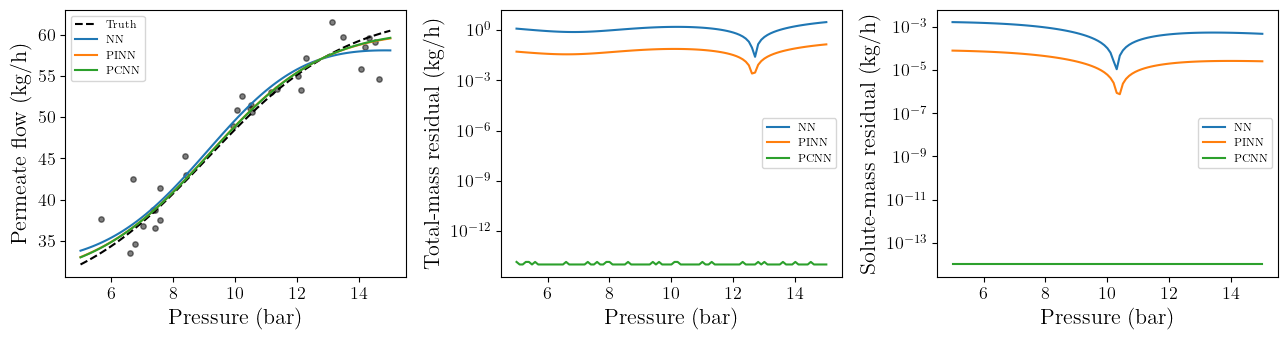

In [5]:
# IPOPT is introduced only for the hard-constrained PCNN.
IPOPT_PATH = shutil.which("ipopt")

if IPOPT_PATH is None:
    raise RuntimeError(
        "IPOPT not found. Activate the workshop environment."
    )

solver = pyo.SolverFactory(
    "ipopt",
    executable=IPOPT_PATH
)

solver.options.update({
    "tol": 1e-8,
    "constr_viol_tol": 1e-9,
    "acceptable_iter": 0,
    "max_iter": 2000,
    "print_level": 0
})


def build_pcnn(Y, start=None):
    start = init if start is None else start

    m = pyo.ConcreteModel()

    m.I = pyo.RangeSet(0, len(P_train)-1)
    m.J = pyo.RangeSet(0, H-1)
    m.K = pyo.RangeSet(0, 3)

    # Same trainable parameters and initialization as PyTorch.
    # No parameter bounds are imposed.
    m.a = pyo.Var(
        m.J,
        initialize=lambda m, j: float(start["a"][j])
    )
    m.b = pyo.Var(
        m.J,
        initialize=lambda m, j: float(start["b"][j])
    )
    m.V = pyo.Var(
        m.J, m.K,
        initialize=lambda m, j, k: float(start["V"][j, k])
    )
    m.d = pyo.Var(
        m.K,
        initialize=lambda m, k: float(start["d"][k])
    )

    x = scaled_pressure(P_train)

    m.h = pyo.Expression(
        m.I, m.J,
        rule=lambda m, i, j:
            pyo.tanh(m.a[j]*float(x[i]) + m.b[j])
    )

    # Normalized network outputs.
    m.q = pyo.Expression(
        m.I, m.K,
        rule=lambda m, i, k:
            m.d[k] + sum(
                m.V[j, k]*m.h[i, j] for j in m.J
            )
    )

    # Physical flow predictions, kg/h:
    # k = 0: Fp, 1: Fr, 2: Sp, 3: Sr.
    m.flow = pyo.Expression(
        m.I, m.K,
        rule=lambda m, i, k:
            float(scale[k])*m.q[i, k]
    )

    # Same normalized data-fitting loss as PyTorch.
    m.data_loss = pyo.Expression(
        expr=sum(
            ((m.q[i, k] - float(Y[i, k]))/float(sigma[k]))**2
            for i in m.I for k in m.K
        )/(4*len(P_train))
    )

    parameters = (
        list(m.a.values())
        + list(m.b.values())
        + list(m.V.values())
        + list(m.d.values())
    )

    m.reg = pyo.Expression(
        expr=sum(v*v for v in parameters)/len(parameters)
    )

    # Hard conservation equalities in physical units (kg/h).
    
    # Total-mass balance: Fp + Fr = F
    # Hidden-activation coefficients must sum to zero
    
    m.mass_weights = pyo.Constraint(
        m.J,
        rule=lambda m, j:
            float(scale[0])*m.V[j, 0]
            + float(scale[1])*m.V[j, 1] == 0.0
    )

    # Physical constant terms must sum to the feed mass flow
    m.mass_bias = pyo.Constraint(
        expr=(
            float(scale[0])*m.d[0]
            + float(scale[1])*m.d[1]
            == float(F)
        )
    )

    # Solute-mass balance: Sp + Sr = F*cf
    # Hidden-activation coefficients must sum to zero
    
    m.solute_weights = pyo.Constraint(
        m.J,
        rule=lambda m, j:
            float(scale[2])*m.V[j, 2]
            + float(scale[3])*m.V[j, 3] == 0.0
    )

    # Physical constant terms must sum to the feed solute flow
    
    m.solute_bias = pyo.Constraint(
        expr=(
            float(scale[2])*m.d[2]
            + float(scale[3])*m.d[3]
            == float(F*cf)
        )
    )

    # No physics penalty: conservation is imposed as constraints
    
    m.obj = pyo.Objective(
        expr=m.data_loss + alpha*m.reg
    )

    return m


def fit_pcnn(Y, start=None):
    m = build_pcnn(Y, start)
    result = solver.solve(m, tee=False)

    if not check_optimal_termination(result):
        raise RuntimeError(
            f"PCNN: {result.solver.termination_condition}"
        )

    theta = {
        "a": np.array([
            pyo.value(m.a[j]) for j in m.J
        ]),
        "b": np.array([
            pyo.value(m.b[j]) for j in m.J
        ]),
        "V": np.array([
            [pyo.value(m.V[j, k]) for k in m.K]
            for j in m.J
        ]),
        "d": np.array([
            pyo.value(m.d[k]) for k in m.K
        ])
    }

    return theta, m

theta_pcnn, model_pcnn = fit_pcnn(q_obs)

models = {
    "NN": theta_nn,
    "PINN": theta_pinn,
    "PCNN": theta_pcnn
}

def balances(q):
    """Dimensionless residuals retained for later UQ cells."""
    return np.column_stack([
        q[:, 0] + q[:, 1] - 1,
        q[:, 2] + q[:, 3] - 1
    ])

def physical_balances(q):
    """Signed total-mass and solute-balance residuals in kg/h."""
    flows = q * scale

    return np.column_stack([
        flows[:, 0] + flows[:, 1] - F,
        flows[:, 2] + flows[:, 3] - F*cf
    ])

def physical_outputs(q):
    flows = q * scale

    if np.any(flows[:, :2] <= 0):
        raise ValueError(
            "Nonpositive total flow; concentrations are undefined."
        )

    cp = flows[:, 2] / flows[:, 0]
    cr = flows[:, 3] / flows[:, 1]

    if (
        np.any(cp < 0) or np.any(cr < 0)
        or np.any(cp > 1) or np.any(cr > 1)
    ):
        raise ValueError(
            "Nonphysical composition: add appropriate output inequalities."
        )

    return np.column_stack([
        flows[:, 0], flows[:, 1], cp, cr
    ])

# Prediction accuracy: separate RMSE for each output in kg/h

print("Test RMSE against noise-free synthetic truth (kg/h)")
print(
    f"{'Model':<8} {'Fp':>12} {'Fr':>12} "
    f"{'Sp':>12} {'Sr':>12}"
)

for name, theta in models.items():
    q = predict(theta, P_test)

    physical_errors = (q - truth(P_test)) * scale
    rmse = np.sqrt(np.mean(physical_errors**2, axis=0))

    physical_outputs(q)

    print(
        f"{name:<8} "
        f"{rmse[0]:12.5f} {rmse[1]:12.5f} "
        f"{rmse[2]:12.5f} {rmse[3]:12.5f}"
    )


# Maximum absolute conservation errors in kg/h

print("\nMaximum absolute balance residuals (kg/h)")
print(
    f"{'Model':<8} "
    f"{'Train mass':>14} {'Train solute':>14} "
    f"{'Test mass':>14} {'Test solute':>14}"
)

for name, theta in models.items():
    train_residuals = physical_balances(
        predict(theta, P_train)
    )
    test_residuals = physical_balances(
        predict(theta, P_test)
    )

    train_max = np.max(np.abs(train_residuals), axis=0)
    test_max = np.max(np.abs(test_residuals), axis=0)

    print(
        f"{name:<8} "
        f"{train_max[0]:14.3e} {train_max[1]:14.3e} "
        f"{test_max[0]:14.3e} {test_max[1]:14.3e}"
    )

assert (
    np.max(
        np.abs(physical_balances(predict(theta_pcnn, P_test)))
    ) < 1e-7
)


# Predictions and absolute conservation errors in physical units

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].plot(
    P_grid,
    truth(P_grid)[:, 0]*F,
    "k--",
    label="Truth"
)

axes[0].scatter(
    P_train,
    q_obs[:, 0]*F,
    c="k",
    s=15,
    alpha=0.5
)

for name, theta in models.items():
    q = predict(theta, P_grid)
    residuals = physical_balances(q)

    axes[0].plot(
        P_grid,
        q[:, 0]*F,
        label=name
    )

    for j in range(2):
        axes[j+1].semilogy(
            P_grid,
            # Plotting floor only: log axes cannot display zero.
            np.maximum(np.abs(residuals[:, j]), 1e-14),
            label=name
        )

axes[0].set_ylabel("Permeate flow (kg/h)")
axes[1].set_ylabel("Total-mass residual (kg/h)")
axes[2].set_ylabel("Solute-mass residual (kg/h)")

for ax in axes:
    ax.set_xlabel("Pressure (bar)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 5. Parameter UQ using a constrained parametric bootstrap

Our fitted weights are estimates obtained from noisy measurements.
How much might they change if we repeated the experiment?

For bootstrap replicate $s=1,\dots,N_s$:

1. Use the fitted PCNN as a plug-in data-generating model.
2. Generate new synthetic measurements at the same pressures:

   $$q_{\omega k,s}
   =\widehat q_k(P_\omega;\widehat\theta)+\epsilon_{\omega k,s},\qquad \omega\in\mathcal S$$

   $$\epsilon_{\omega k,s}\sim\mathcal N(0,\sigma_k^2)$$

3. Refit the same equality-constrained estimator to obtain
   $\theta_s$.
4. Collect the refitted parameters and their predictions.

This is a frequentist parametric bootstrap, not Bayesian posterior sampling,
variational inference, or MCMC.

Assumptions:
- The specified measurement-noise model is appropriate.
- Feed conditions are known exactly.
- The fitted model is an adequate approximation to the process.
- Structural model uncertainty is excluded.

Use $N_s=30$ refits for the live demonstration. For reported uncertainty intervals,
increase this to several hundred and check quantile stability.

Warm starts keep the refits near the original fitted solution. NN
weights can be weakly identifiable and have permutation/sign symmetries.
Therefore, individual weight ranges are local diagnostics rather than
confidence intervals for physical parameters.

Failed solves halt the UQ workflow rather than being silently discarded.

In [6]:
B = 30  # Increase to 300–1000 for a convergence study

rng_boot = np.random.default_rng(SEED + 1)
q_center = predict(theta_pcnn, P_train)

boot_theta = []
t0 = time.perf_counter()

for b in range(B):
    Yb = q_center + rng_boot.normal(size=q_center.shape)*sigma

    try:
        tb, _ = fit_pcnn(Yb, start=theta_pcnn)
    except RuntimeError as exc:
        raise RuntimeError(
            f"Bootstrap refit {b+1}/{B} failed; "
            "investigate before UQ."
        ) from exc

    boot_theta.append(tb)

    if (b+1) % 10 == 0:
        print(f"Completed {b+1}/{B} refits")

print(f"Bootstrap time: {time.perf_counter()-t0:.1f} s")

def pack(theta):
    return np.concatenate([
        theta["a"],
        theta["b"],
        theta["V"].ravel(),
        theta["d"]
    ])

T = np.stack([pack(t) for t in boot_theta])

parameter_names = (
    [f"a{j}" for j in range(H)]
    + [f"b{j}" for j in range(H)]
    + [f"V{j}{k}" for j in range(H) for k in range(4)]
    + [f"d{k}" for k in range(4)]
)

parameter_covariance = np.cov(T, rowvar=False)
lo, hi = np.quantile(T, [0.025, 0.975], axis=0)

print("Local bootstrap weight summary (not physical parameters):")

for name, estimate, sd, l, u in zip(
    parameter_names,
    pack(theta_pcnn),
    T.std(0, ddof=1),
    lo,
    hi
):
    print(
        f"{name:>4}: fit={estimate: .4f}, SD={sd:.4f}, "
        f"percentile range=[{l:.4f}, {u:.4f}]"
    )

print("Covariance shape:", parameter_covariance.shape)

# Equality constraints imply dependent parameters and a singular covariance
# Do not invert this covariance or independently perturb the fitted weights

Completed 10/30 refits
Completed 20/30 refits
Completed 30/30 refits
Bootstrap time: 23.1 s
Local bootstrap weight summary (not physical parameters):
  a0: fit= 0.9446, SD=0.2856, percentile range=[0.2892, 1.1853]
  a1: fit= 1.2060, SD=0.2771, percentile range=[0.7871, 1.7061]
  b0: fit= 0.0345, SD=0.3015, percentile range=[-0.5585, 0.2879]
  b1: fit= 0.1780, SD=0.1611, percentile range=[-0.1409, 0.4010]
 V00: fit=-0.0742, SD=0.1735, percentile range=[-0.3790, 0.2114]
 V01: fit= 0.0742, SD=0.1735, percentile range=[-0.2114, 0.3790]
 V02: fit= 0.0757, SD=0.0394, percentile range=[0.0217, 0.1614]
 V03: fit=-0.0757, SD=0.0394, percentile range=[-0.1614, -0.0217]
 V10: fit= 0.2272, SD=0.1243, percentile range=[-0.0250, 0.3960]
 V11: fit=-0.2272, SD=0.1243, percentile range=[-0.3960, 0.0250]
 V12: fit=-0.0467, SD=0.0368, percentile range=[-0.1100, 0.0056]
 V13: fit= 0.0467, SD=0.0368, percentile range=[-0.0056, 0.1100]
  d0: fit= 0.4519, SD=0.0459, percentile range=[0.2951, 0.4590]
  d1: fi

### 6. Propagate parameter uncertainty to predictions

For every bootstrap parameter set, calculate

$$\widehat q_s(P)=\mathrm{ML}_{\theta_s}(x(P)),\qquad s=1,\dots,N_s$$

Pointwise 2.5th and 97.5th percentiles provide an approximate 95% bootstrap
confidence band for the fitted response, conditional on our assumptions.

The plotted bands represent uncertainty in the fitted process response
due to parameter estimation. No additional future-measurement noise
is added to these predictions.

Every bootstrap PCNN prediction satisfies the conservation constraints.

For concentration predictions, calculate the ratio separately for each sample:

$$c_{p,s}=\frac{S_{p,s}}{F_{p,s}}$$

Then compute quantiles. Taking ratios of marginal interval endpoints does
not correctly propagate uncertainty.

Similarly, independently selected upper/lower endpoints across different
outputs do not necessarily form a mass-conserving state.

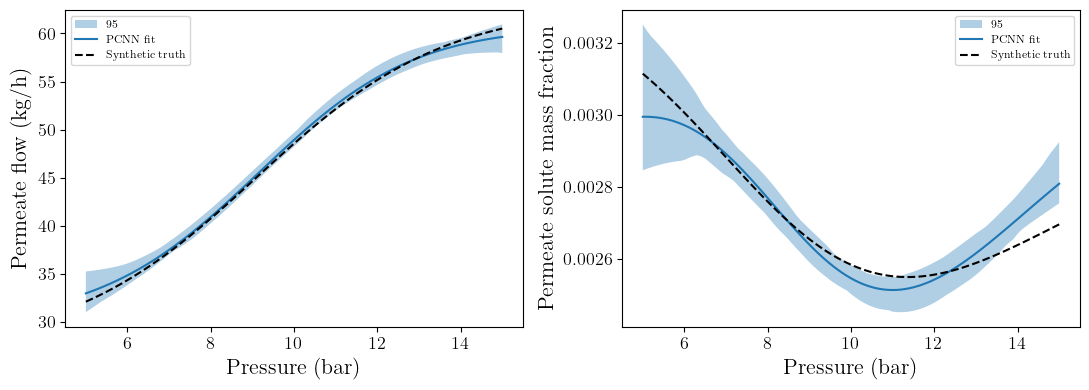

Largest absolute balance residual across bootstrap predictions (kg/h): 2.842170943040401e-14


In [7]:
# Propagate bootstrap parameter uncertainty to predictions.
Q = np.stack([
    predict(t, P_grid)
    for t in boot_theta
])

# Convert each sample to physical flows and concentrations.
D = np.stack([
    physical_outputs(q)
    for q in Q
])

D_fit = physical_outputs(predict(theta_pcnn, P_grid))
D_true = physical_outputs(truth(P_grid))

lower, upper = np.quantile(
    D, [0.025, 0.975], axis=0
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, j, ylabel in zip(
    axes,
    [0, 2],
    ["Permeate flow (kg/h)", "Permeate solute mass fraction"]
):
    ax.fill_between(
        P_grid,
        lower[:, j],
        upper[:, j],
        alpha=0.35,
        label="95% response bootstrap band"
    )
    ax.plot(
        P_grid, D_fit[:, j],
        label="PCNN fit"
    )
    ax.plot(
        P_grid, D_true[:, j],
        "k--", label="Synthetic truth"
    )
    ax.set(
        xlabel="Pressure (bar)",
        ylabel=ylabel
    )
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Verify conservation across the bootstrap predictions.
max_balance = max(
    np.max(np.abs(physical_balances(q)))
    for q in Q
)

print(
    "Largest absolute balance residual across bootstrap predictions (kg/h):",
    max_balance
)
assert max_balance < 1e-7

### 7. Key takeaways

- Mass balances regularize the NN: the PINN and PCNN predict the flows more accurately than the unconstrained NN (Module 2).
- The PCNN satisfies the balances exactly, also for every bootstrap replicate; physics constraints restrict the estimation
  problem in the same way as constraints on parameters (Module 3).
- Bootstrapping quantifies uncertainty by repeated estimation; it is simple but requires many refits (Module 3).
- Tools: PyTorch (NN, PINN), Pyomo and Ipopt (constrained training), NumPy (bootstrap) (Module 4).
- Data determine the fit, hard constraints determine feasibility, and UQ quantifies uncertainty under stated
  assumptions; each must be evaluated separately.

### 8. Optional exercises

1. **Accuracy versus feasibility**

   Can a model conserve mass perfectly and still predict the wrong separation?

   Yes. Balances restrict admissible outputs, but do not identify the
   pressure–recovery relationship.

2. **Penalty sensitivity**

   Repeat PINN training using `fit_torch(q_obs, lam=value)` for
   $\lambda_p=0.1,1,10,100$. Compare data loss, test RMSE, and balance
   violations. In a real workflow, choose the penalty using a separate
   validation set, not the test set.

3. **Amount of data**

   Change the number of training experiments from 30 to 15 or 60.
   Rerun all cells and compare uncertainty bands.

4. **Measurement noise**

   Double `sigma`, regenerate the measurements, and rerun.
   Compare changes in the widths of the response bootstrap bands.

5. **Extrapolation**

   The PCNN coefficient constraints preserve balances outside the training
   pressure range, but neither accuracy nor valid compositions is guaranteed.

6. **Additional physical knowledge**

   Consider positivity and

   $$0\le S_p\le F_p,\qquad 0\le S_r\le F_r$$

   These can be imposed as inequalities at selected design points.
   Grid-based constraints alone do not establish feasibility everywhere.

   For an isolated penalty-versus-equality comparison, give all models the
   same additional physical assumptions.

### References

- Raissi, M., Perdikaris, P., and Karniadakis, G. E. (2019).
  "Physics-informed neural networks: A deep learning framework for solving
  forward and inverse problems involving nonlinear partial differential equations."
  Journal of Computational Physics, 378, 686–707.
  https://doi.org/10.1016/j.jcp.2018.10.045

- Mukherjee, A. and Bhattacharyya, D. (2024). "On the Development of Steady-State and Dynamic Mass-Constrained
  Neural Networks Using Noisy Transient Data."
  Computers & Chemical Engineering, 187, 108722.
  https://doi.org/10.1016/j.compchemeng.2024.108722

- Pyomo solver recipes:
  https://pyomo.readthedocs.io/en/stable/howto/solver_recipes.html

- IPOPT options:
  https://coin-or.github.io/Ipopt/OPTIONS.html

- PyTorch Adam:
  https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html

- PyTorch L-BFGS:
  https://docs.pytorch.org/docs/stable/generated/torch.optim.LBFGS.html